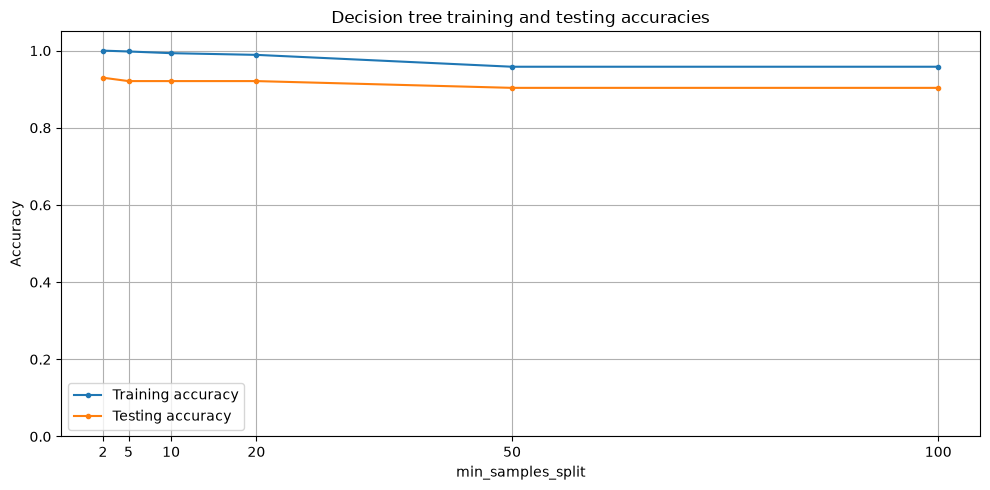

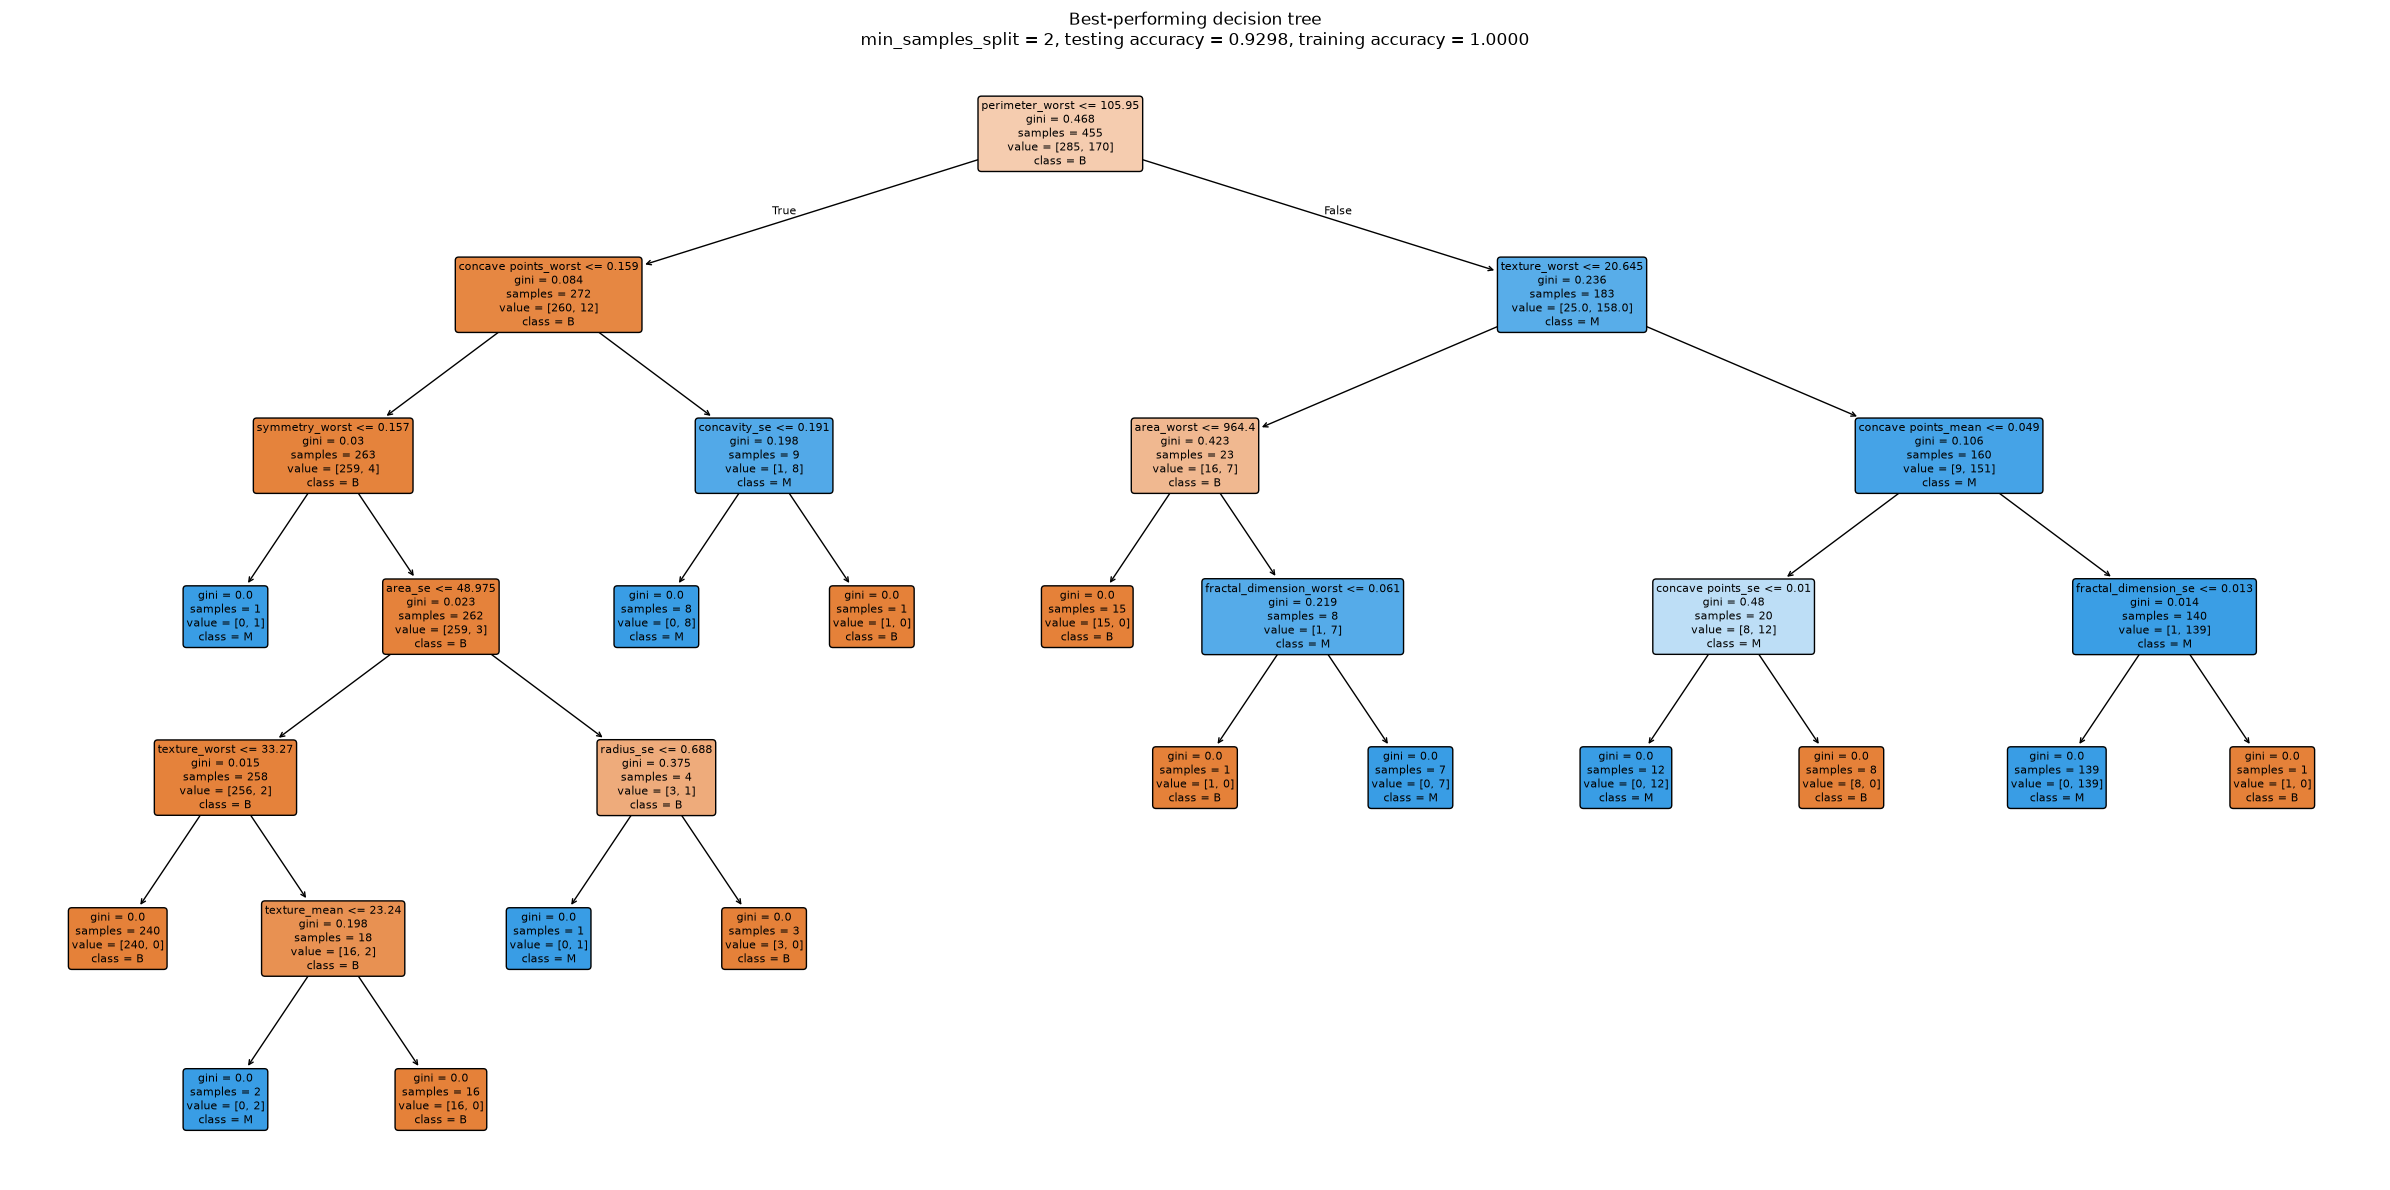

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score


df = pd.read_csv("breast_cancer.csv")

X = df.drop(columns="diagnosis")
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,  
    test_size=0.20, # 20% usado para teste
    stratify=y, # faz com que a proporcao de M e B em ambos conjuntos seja razoavel
    random_state=1 # sempre que corre output igual, se None variaria
)


min_samples_split_values = [2, 5, 10, 20, 50, 100] # cada valor representa nº de amostras em que tree pode ser dividio
# caso 2-> um no com 2 ou mais amostras pode ser dividido #neste caso arvore mt profunda pois mtas folhas 
training_accuracies = []
testing_accuracies = []
models = []

for value in min_samples_split_values:

    model = DecisionTreeClassifier(
        min_samples_split=value,
        random_state=1
    ).fit(X_train, y_train)


    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    training_accuracies.append(train_accuracy)
    testing_accuracies.append(test_accuracy)
    models.append(model)


plt.figure(figsize=(10, 5))

plt.plot(
    min_samples_split_values,
    training_accuracies,
    marker=".",
    label="Training accuracy"
)

plt.plot(
    min_samples_split_values,
    testing_accuracies,
    marker=".",
    label="Testing accuracy"
)

plt.xlabel("min_samples_split")
plt.ylabel("Accuracy")
plt.title("Decision tree training and testing accuracies")
plt.xticks(min_samples_split_values)
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


l = len(min_samples_split_values)
best_index = 0
for i in range(1, l):
    if testing_accuracies[i] >= testing_accuracies[best_index]:
        best_index = i


best_model = models[best_index]
best_min_samples_split = min_samples_split_values[best_index]
best_training_accuracy = training_accuracies[best_index]
best_testing_accuracy = testing_accuracies[best_index]


plt.figure(figsize=(24, 12))

plot_tree(
    best_model,
    feature_names=X.columns,
    class_names=[str(label) for label in best_model.classes_],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title(
    "Best-performing decision tree\n"
    f"min_samples_split = {best_min_samples_split}, "
    f"testing accuracy = {best_testing_accuracy:.4f}"
    f", training accuracy = {best_training_accuracy:.4f}"
)

plt.tight_layout()
plt.show()

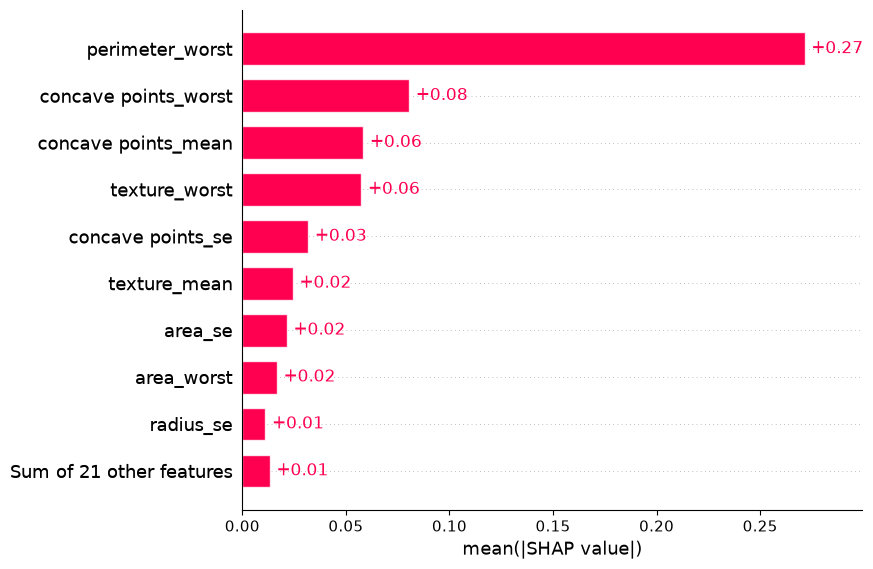

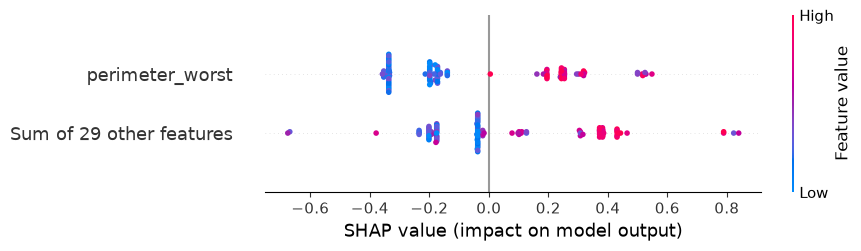

'\nEx: perimeter_worst vermelho significa alto, influencia diretamente a prob\ndo paciente ter tumor maligno (azul -> baixo -> tumor benigno)\nconcluimos juntamente com o grafico de barras que perimeter worst\ntem um grande impacto a afirmar tipo de tumor\n'

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import shap


df = pd.read_csv("breast_cancer.csv")

X = df.drop(columns="diagnosis")
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1,
    stratify=y
)


BEST_MIN_SAMPLES_SPLIT = 2  

best_tree = DecisionTreeClassifier(
    min_samples_split=BEST_MIN_SAMPLES_SPLIT,
    random_state= 1
).fit(X_train, y_train)

explainer = shap.TreeExplainer(best_tree) #quanto cada feature contribui para as decisões
shap_values = explainer(X_test) #contribuição de cada uma dessas features para o output do modelo


classes_list = list(best_tree.classes_)
malignant_index = classes_list.index("M")


shap_malignant = shap_values[:, :, malignant_index]

# a)
shap.plots.bar(shap_malignant)
plt.show()

# b)
shap.plots.beeswarm(shap_malignant, max_display=2)
plt.show()


#Ex: perimeter_worst vermelho significa alto, influencia diretamente a prob
#do paciente ter tumor maligno (azul -> baixo -> tumor benigno)
#concluimos juntamente com o grafico de barras que perimeter worst
#tem um grande impacto a afirmar tipo de tumor


In [ ]:
'''
escrever aqui a resposta da 3 (ou 2)
'''

''

In [ ]:
'''
escrever aqui as repostas da 2 (ou 3)
'''

In [ ]:
import pandas as pd
from sklearn.feature_selection import f_classif

df = pd.read_csv("breast_cancer.csv")
target = "diagnosis"
X = df.drop(columns=[target]) # var de entrada
y = df[target] # var objetivo

f_statistics, p_values = f_classif(X, y)

results = pd.DataFrame({
    "Variable": X.columns,
    "F_statistic": f_statistics,
    "p_value": p_values
})

results = results.sort_values(by="F_statistic", ascending=False)

results.insert(0,"Rank",range(1, len(results) + 1))

results = results[results["p_value"] <= 0.05]
finalList = results.to_string(index=False)
print(finalList)

 Rank                Variable  F_statistic       p_value
    1    concave points_worst   964.385393 1.969100e-124
    2         perimeter_worst   897.944219 5.771397e-119
    3     concave points_mean   861.676020 7.101150e-116
    4            radius_worst   860.781707 8.482292e-116
    5          perimeter_mean   697.235272 8.436251e-101
    6              area_worst   661.600206  2.828848e-97
    7             radius_mean   646.981021  8.465941e-96
    8               area_mean   573.060747  4.734564e-88
    9          concavity_mean   533.793126  9.966556e-84
   10         concavity_worst   436.691939  2.464664e-72
   11        compactness_mean   313.233079  3.938263e-56
   12       compactness_worst   304.341063  7.069816e-55
   13               radius_se   268.840327  9.738949e-50
   14            perimeter_se   253.897392  1.651905e-47
   15                 area_se   243.651586  5.895521e-46
   16           texture_worst   149.596905  1.078057e-30
   17        smoothness_worst  